In [13]:
# ===========================================================================
# Bibliotheken
# ===========================================================================
# Alle teamleden gebruiken exact dezelfde versies (zie requirements.txt), zodat
# de resultaten reproduceerbaar en onderling vergelijkbaar zijn.
from typing import Any

# --- Data en visualisatie ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Hulptools ---
import warnings
import optuna
import sklearn

# --- Scikit-learn: bouwstenen ---
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV  # kanscalibratie voor SVM
from sklearn.exceptions import ConvergenceWarning       # specifiek op te vangen warning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# --- Scikit-learn: modellen ---
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
)
from sklearn.svm import SVC, LinearSVC

# --- Externe modellen en imbalance-technieken ---
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline  # pipeline die SMOTE ondersteunt
from imblearn.over_sampling import SMOTE

# Één vaste random_state voor het hele project. Dezelfde waarde voor alle
# teamleden betekent: dezelfde train/validatiesplit en dus vergelijkbare scores.
RANDOM_STATE = 42

# Opmaak: waarschuwingen zouden de output overspoelen.
# warnings.filterwarnings('ignore')

# Opdracht 1: Voorspel Herseninfarct (Stroke Prediction)

**Competitie:** Predicting stroke 2026-27 | Kaggle  
**Teamnaam:** Groep 4  
**Teamleden & Kaggle Usernames:**
- Kaman - [Kaggle Username 1]
- Alex - [Kaggle Username 2]
- Pablo - [Kaggle Username 3]

---

## 1. Inleiding

In dit project werken we als junior data scientists bij *MedPredict*. Het doel is om een
machine learning model te ontwikkelen dat op basis van demografische, leefstijl- en
medische gegevens kan voorspellen of een patiënt een verhoogd risico loopt op een
herseninfarct (stroke). Dit model ondersteunt zorgprofessionals bij preventie en
gerichte opvolging.

**Opbouw van dit notebook**

| Sectie | Inhoud |
|--------|--------|
| 1 | Inleiding |
| 2 | Data en exploratieve data-analyse (EDA) |
| 3 | Data opschonen en voorbereiden |
| 4 | Modeltraining: vaste werkwijze voor alle modellen |
| 5 | Modellen: SVM, Decision Tree, Random Forest, GBDT en XGBoost |
| 6 | Zelf samengesteld ensemble (VotingClassifier) |

Alle teamleden gebruiken dezelfde `random_state` (42), dezelfde train/validatiesplit en
dezelfde beoordelingsmetriek (F1-score). Zo zijn de resultaten tussen modellen en
teamleden onderling vergelijkbaar.

In [14]:
# Snelle eerste blik op de ruwe trainingsdata, nog vóór het opschonen.
# Let op het aantal niet-null waarden per kolom: daaruit blijkt of er
# ontbrekende waarden zijn (bij `bmi` kan dat het geval zijn).
train_df = pd.read_csv("train.csv")
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

## 2. Data en exploratieve data-analyse (EDA)

### 2.1 Uitleg van de kolommen

De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen:
- **id**: unieke identificatie van de patiënt. Deze kolom wordt niet als voorspeller gebruikt.
- **age**: leeftijd van de patiënt in jaren.
- **hypertension**: indicator voor hoge bloeddruk; 0 = nee, 1 = ja.
- **heart_disease**: indicator voor hartziekte; 0 = nee, 1 = ja.
- **avg_glucose_level**: gemiddeld glucosegehalte in het bloed.
- **bmi**: Body Mass Index, een maat voor gewicht in verhouding tot lengte.
- **gender_Female**, **gender_Male**, **gender_Other**: dummyvariabelen voor het geregistreerde geslacht.
- **ever_married_No**, **ever_married_Yes**: dummyvariabelen voor de burgerlijke staat.
- **work_type_Govt_job**, **work_type_Never_worked**, **work_type_Private**, **work_type_Self-employed**, **work_type_children**: dummyvariabelen voor het soort werk.
- **Residence_type_Rural**, **Residence_type_Urban**: dummyvariabelen voor het type woonomgeving.
- **smoking_status_formerly smoked**, **smoking_status_never smoked**, **smoking_status_smokes**: dummyvariabelen voor rookstatus. Een eventuele niet-rokerstatus die niet als aparte kolom voorkomt, is de referentiecategorie.
- **stroke**: doelvariabele; 1 betekent dat de patiënt een herseninfarct heeft gehad en 0 dat niet. Deze kolom ontbreekt in `test.csv`.

In [15]:
class DataLoader:
    """
    Laadt de train- en testdataset in en maakt ze direct geschikt voor sklearn.

    Twee dingen worden hier geregeld:
    1. Inlezen van de CSV-bestanden (met header, dus de standaard header=0).
    2. Omzetten van kolommen met dtype `bool` naar 0/1.

    Waarom stap 2? De dummyvariabelen (gender, work_type, ...) staan in het
    CSV-bestand als True/False. Sommige sklearn- en XGBoost-versies gaan daar
    niet goed mee om, terwijl 0/1 altijd werkt. De omzetting gebeurt voor train
    en test afzonderlijk, maar met dezelfde kolomnamen, zodat de kolomvolgorde
    in beide datasets identiek blijft.
    """

    def __init__(self, train_path, test_path):
        self.train_path = train_path
        self.test_path = test_path

    def load_data(self):
        """Laadt de train- en testdataset en converteert booleans naar 0/1."""
        self.train_df = pd.read_csv(self.train_path)
        self.test_df = pd.read_csv(self.test_path)

        # Zoek de booleankolommen in de trainingsset en pas dezelfde conversie
        # toe op de testset, zodat beide datasets dezelfde dtypes houden.
        bool_cols = self.train_df.select_dtypes(include=['bool']).columns
        for col in bool_cols:
            self.train_df[col] = self.train_df[col].astype(int)
            if col in self.test_df.columns:
                self.test_df[col] = self.test_df[col].astype(int)

        return self.train_df, self.test_df


# Inladen van de data
loader = DataLoader('train.csv', 'test.csv')
train_df, test_df = loader.load_data()

# Controle: klopt het aantal rijen en kolommen met wat we verwachten?
# train.csv bevat ook de doelvariabele `stroke`, test.csv niet.
print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()

Train Data Shape: (33550, 22)
Test Data Shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
1,72295,75.0,1,0,215.17,48.0,1,0,0,0,...,0,0,1,0,1,0,0,1,0,0
2,26451,15.0,0,0,135.22,19.0,0,1,0,1,...,0,1,0,0,1,0,0,1,0,0
3,65210,47.0,0,0,64.89,28.2,0,1,0,0,...,0,0,1,0,0,1,0,1,0,0
4,69299,49.0,0,0,222.34,28.8,0,1,0,0,...,0,0,1,0,1,0,1,0,0,0


### 2.2 Minimale vereisten voor machine learning met scikit-learn

Scikit-learn verwacht dat de invoervariabelen numeriek zijn en dat het gekozen algoritme
met ontbrekende waarden kan omgaan. De dummyvariabelen zijn booleans en worden bij het
inladen omgezet naar 0 en 1. In deze aangeleverde dataset zijn geen ontbrekende
BMI-waarden aangetroffen. De imputatiestap blijft wel in de pipeline staan als robuuste
bescherming wanneer een vergelijkbare dataset later wél ontbrekende waarden bevat.

De dataset bevat 33.550 patiënten. Daarvan hebben 517 patiënten `stroke = 1` en 33.033
patiënten `stroke = 0`; het positieve aandeel is ongeveer 1,54%. Daarmee is de target
sterk imbalanced. De kolom `id` is een identificatienummer en wordt verwijderd, omdat
deze geen inhoudelijke voorspeller is.

### 2.3 Datatypes en basisstatistieken

In [16]:
def show_basic_stats(df):
    """
    Toont datatypes, samenvattende statistieken en ontbrekende waarden.

    Doel van deze functie is het beantwoorden van de minimale vereisten uit de
    opdracht:
    - Zijn alle kolommen numeriek (of op zijn minst bruikbaar)? -> dtypes-overzicht
    - Wat is de schaal van de variabelen? -> describe(), nodig om te bepalen of
      standaardisatie zin heeft (een kolom met waarden rond 100 domineert anders
      een kolom met waarden rond 0,5).
    - Zijn er ontbrekende waarden? -> isnull().sum(); die moeten later geïmputeerd
      worden, anders weigert het model te trainen.
    """
    print("--- Data Types ---")
    print(df.dtypes.value_counts())

    print("\n--- Basisstatistieken ---")
    display(df.describe())

    # Check voor missing values: som over alle kolommen. Alleen kolommen met
    # daadwerkelijk ontbrekende waarden worden getoond, anders wordt de output
    # onnodig lang.
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")


show_basic_stats(train_df)

--- Data Types ---
int64      19
float64     3
Name: count, dtype: int64

--- Basisstatistieken ---


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,...,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.597079,0.402742,0.000179,0.361371,...,0.004203,0.574635,0.152787,0.144501,0.499970,0.500030,0.168733,0.375618,0.148048,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.490492,0.490457,0.013372,0.480405,...,0.064693,0.494406,0.359787,0.351602,0.500007,0.500007,0.374522,0.484289,0.355153,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,1.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Geen missing values gevonden in de basisinspectie.


### 2.4 Relaties tussen variabelen (visualisaties)

We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (`stroke`).
Eerst met boxplots voor de continue variabelen, daarna met een correlatiematrix voor de
kernvariabelen. Dit bepaalt welke variabelen waarschijnlijk voorspellend zijn.

C:\Users\phtij\AppData\Local\Temp\ipykernel_36608\1336553462.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', data=df, ax=axes[0, 0], palette='Set2')
C:\Users\phtij\AppData\Local\Temp\ipykernel_36608\1336553462.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], palette='Set2')
C:\Users\phtij\AppData\Local\Temp\ipykernel_36608\1336553462.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0], palette='Set2')
C:\Users\phtij\A

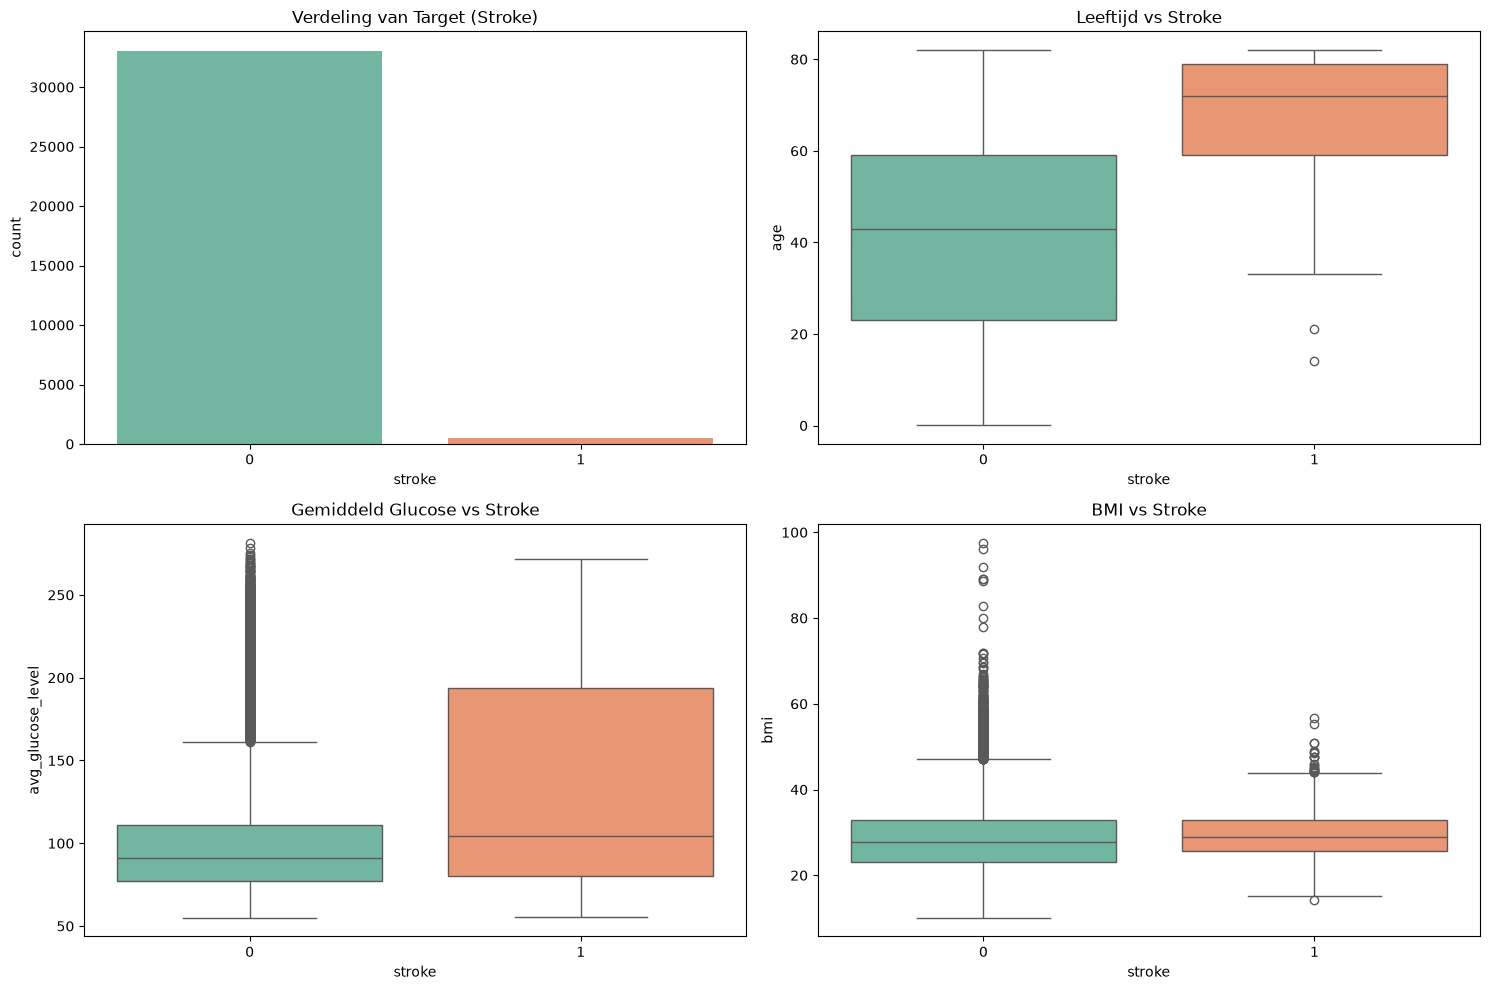

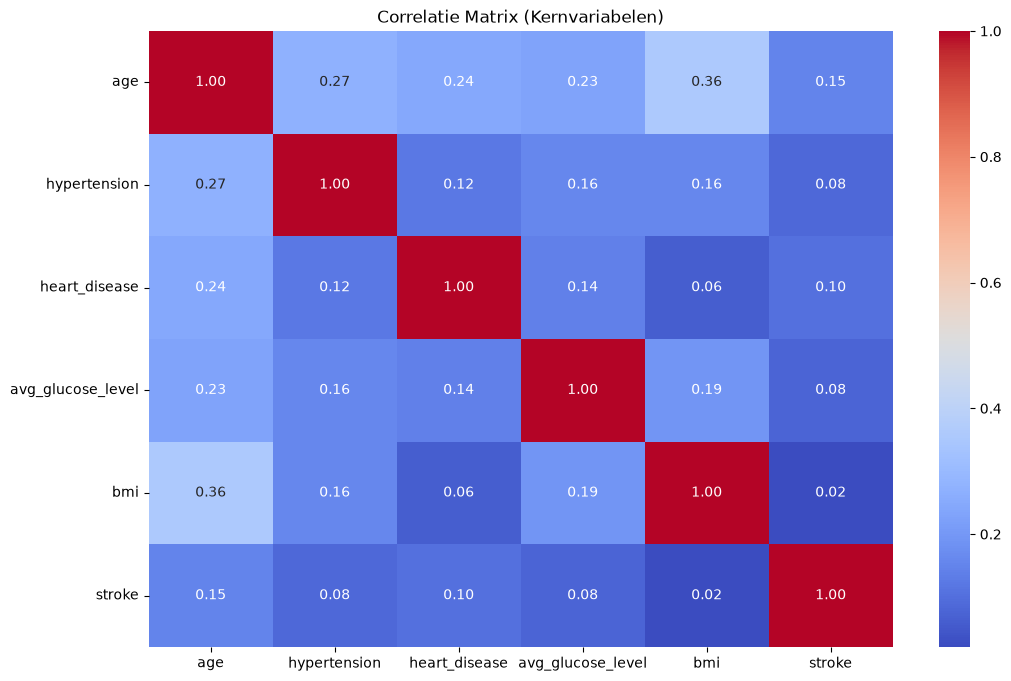

In [17]:
def plot_eda(df):
    """
    Maakt vier visualisaties die de belangrijkste eigenschappen van de data tonen:

    1. Verdeling van de target -> laat direct zien hoe sterk de klassen uit
       balans zijn. Dat is de aanleiding voor de imbalance-vergelijking verderop.
    2. Leeftijd vs stroke -> boxplot: is er een verschil in leeftijdsverdeling
       tussen de twee klassen?
    3. Glucose vs stroke -> zelfde vraag voor het glucosegehalte.
    4. BMI vs stroke -> zelfde vraag voor de BMI.

    Boxplots zijn hier geschikt omdat ze mediaan, spreiding en uitschieters in
    één oogopslag tonen, ook wanneer de klassen erg ongelijk verdeeld zijn.
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Verdeling van Stroke (Imbalanced check)
    sns.countplot(x='stroke', data=df, ax=axes[0, 0], palette='Set2')
    axes[0, 0].set_title('Verdeling van Target (Stroke)')

    # 2. Leeftijd vs Stroke
    sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], palette='Set2')
    axes[0, 1].set_title('Leeftijd vs Stroke')

    # 3. Glucose vs Stroke
    sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0], palette='Set2')
    axes[1, 0].set_title('Gemiddeld Glucose vs Stroke')

    # 4. BMI vs Stroke
    sns.boxplot(x='stroke', y='bmi', data=df, ax=axes[1, 1], palette='Set2')
    axes[1, 1].set_title('BMI vs Stroke')

    plt.tight_layout()
    plt.show()


plot_eda(train_df)

# --- Correlatiematrix -------------------------------------------------------
# We selecteren alleen de numerieke kernvariabelen voor de correlatie heatmap.
# De dummyvariabelen laten we weg: die hebben een andere schaal en zouden het
# beeld vertroebelen.
# Let op de eenheden: de Pearson-correlatie is hier vooral bruikbaar als
# rangorde, niet als bewijs van causaliteit.
plt.figure(figsize=(12, 8))
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlatie Matrix (Kernvariabelen)')
plt.show()

### 2.5 Belangrijkste bevindingen van de EDA

1. **Zeer imbalanced dataset**: het overgrote deel van de patiënten heeft geen stroke (0). Slechts een klein percentage heeft wel een stroke (1). Dit bepaalt de hele modelaanpak: accuracy is een misleidende maatstaf en de classificatiedrempel moet getuned worden.
2. **Leeftijd**: patiënten met een stroke zijn gemiddeld significant ouder.
3. **Glucose & BMI**: er is een zichtbare correlatie; hogere glucosewaarden en extremere BMI-waarden komen vaker voor bij de stroke-groep.
4. **Hypertension & heart disease**: deze binaire variabelen tonen een positieve correlatie met de target.

Deze bevindingen verklaren waarom de latere modellen vooral `age`, `avg_glucose_level`,
`bmi`, `hypertension` en `heart_disease` gebruiken om te splitsen.

---

## 3. Data opschonen en voorbereiden

### 3.1 Irrelevante kolommen verwijderen

We verwijderen de `id`-kolom: dit is een identificatienummer zonder voorspellende waarde.
Omdat scikit-learn niet bij alle algoritmen goed met ontbrekende waarden omgaat, voegen we
daarnaast een imputatiestap toe in de modeling pipeline (zie sectie 4).

In [18]:
def clean_data(train_df, test_df):
    """
    Splitst de ingelezen data in features en target en verwijdert irrelevante kolommen.

    - `id` verdwijnt uit zowel train als test: het is een identificatienummer en
      heeft geen voorspellende waarde. Een model dat op `id` leunt, leert ruis.
    - `stroke` is de doelvariabele en mag dus niet in de features terechtkomen,
      anders voorspelt het model de uitkomst met de uitkomst zelf.
    - `test_df` bevat geen `stroke`-kolom; daar is `id` nodig om de submission
      later aan de juiste patiënten te koppelen. Vandaar dat `ids_test` hieronder
      apart bewaard wordt.

    Retour: X_train (features), y_train (target) en X_test (features).
    """
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']

    X_test = test_df.drop(columns=['id'])

    return X_train, y_train, X_test


X_train, y_train, X_test = clean_data(train_df, test_df)

# Bewaar de test-ids: die zijn nodig om de voorspellingen in de submission aan
# de juiste patiënt te koppelen.
ids_test = test_df['id']

# Controle: hieronder worden de overgebleven kolommen getoond. `id` en `stroke`
# mogen daar niet meer tussen staan, en train en test moeten exact dezelfde
# kolommen in dezelfde volgorde hebben.
display(X_train.columns)

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No',
       'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked',
       'work_type_Private', 'work_type_Self-employed', 'work_type_children',
       'Residence_type_Rural', 'Residence_type_Urban',
       'smoking_status_formerly smoked', 'smoking_status_never smoked',
       'smoking_status_smokes'],
      dtype='str')

### 3.2 Standaardisatie van de data

**Wat is het?** Standaardisatie (bijv. via `StandardScaler`) transformeert data zodat het
een gemiddelde van 0 en een standaardafwijking (sigma) van 1 heeft. De formule is:
$Zscore = \frac{Populatie - Gemiddelde}{Sigma}$.

**Wanneer gewenst?** Het is essentieel voor afstand-gebaseerde algoritmen (zoals SVM en
KNN) en voor algoritmen die gradient descent gebruiken (zoals logistic regression). Zonder
standaardisatie domineren variabelen met een grote schaal (zoals `avg_glucose_level` ~100)
de afstandsberekening ten opzichte van variabelen met een kleine schaal (zoals `age` of
dummyvariabelen 0/1).

**Waarde voor deze dataset:** Voor boom-gebaseerde modellen (Decision Tree, Random Forest,
GBDT, XGBoost) is standaardisatie *niet* strikt noodzakelijk, omdat zij splitsen op basis
van drempelwaarden. Omdat we ook SVM gebruiken, **passen we standaardisatie toe in de
pipeline** zodat alle modellen op dezelfde, eerlijke manier worden voorbereid.

### 3.3 Imbalanced data

De target is sterk imbalanced: slechts 517 van de 33.550 patiënten heeft `stroke = 1`
(ongeveer 1,54%). Daarom vergelijken we technieken die de minderheidsklasse beter laten
meewegen:

1. **SMOTE** (Synthetic Minority Over-sampling Technique; Chawla et al., 2002) genereert
   synthetische voorbeelden van de minderheidsklasse door te interpoleren tussen bestaande
   punten. Dit gebeurt *binnen* de pipeline, dus alleen op de trainingsfold — anders lekt er
   informatie uit de validatiefold en wordt de score te optimistisch.
2. **class_weight='balanced'** verhoogt bij modellen die dit ondersteunen de straf voor
   fouten op de minderheidsklasse. XGBoost gebruikt hiervoor `scale_pos_weight`.

Deze technieken worden niet tegelijk toegepast: bij SMOTE én class weights wordt de
minderheidsklasse dubbel gecompenseerd. Per model wordt met cross-validation op F1-score
bepaald welke aanpak het beste werkt.

In [19]:
def maak_pipeline(model: object, use_smote: bool = True) -> object:
    """
    Bouwt één pipeline met alle voorbewerking plus het model.

    De volgorde van de stappen is bewust gekozen:

    1. `SimpleImputer(strategy='median')` - vult ontbrekende waarden met de
       mediaan. De mediaan is hier geschikter dan het gemiddelde, omdat
       `avg_glucose_level` en `bmi` scheef verdeeld zijn en gevoelig zijn voor
       uitschieters.
    2. `StandardScaler` - zet elke feature op gemiddelde 0 en standaardafwijking 1.
       Nodig voor SVM; voor de boommodellen onschadelijk.
    3. `SMOTE` (optioneel) - maakt synthetische voorbeelden van de
       minderheidsklasse aan.
    4. het model zelf.

    Belangrijk: alle stappen zitten in *één* pipeline die binnen elke
    cross-validation-fold opnieuw wordt gefit. Daardoor wordt SMOTE alleen op de
    trainingsfold toegepast en lekt er geen informatie uit de validatiefold. Zou
    je SMOTE vooraf op de hele dataset toepassen, dan scoort het model te
    optimistisch en zakt het op de leaderboard in.

    Met SMOTE is een `ImbPipeline` nodig (uit imblearn); zonder SMOTE volstaat de
    gewone sklearn `Pipeline`. Beide hebben dezelfde API, dus de rest van de code
    hoeft geen verschil te kennen.

    Parameters
    ----------
    model : sklearn classifier
        Het te gebruiken model.
    use_smote : bool
        Of SMOTE toegepast moet worden.

    Returns
    -------
    Pipeline
        De volledige pipeline.
    """
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]

    if use_smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        return ImbPipeline(steps=steps + [('classifier', model)])
    return Pipeline(steps=steps + [('classifier', model)])

### 3.4 Voorbereiding van de dataset

Alle teamleden gebruiken dezelfde train/validatiesplit en dezelfde `random_state` (42).
De dataset bevat een `id`-kolom die niet voorspellend is en dus verwijderd wordt.

De split is *stratified*: de verhouding tussen `stroke = 0` en `stroke = 1` blijft gelijk
in de trainings- en de validatieset. Dat is noodzakelijk omdat er anders folds kunnen
ontstaan met extreem weinig positieve gevallen (of zelfs nul).

In [20]:
def load_stroke_data(train_path: str, test_path: str) -> tuple:
    """
    Laadt de stroke datasets en verwijdert irrelevante kolommen.

    Parameters
    ----------
    train_path : str
        Pad naar train.csv
    test_path : str
        Pad naar test.csv

    Returns
    -------
    tuple
        X_train, y_train, X_test, ids_test
    """
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    # Zet de dummyvariabelen om van bool naar 0/1, net als in DataLoader.
    # Zonder deze stap blijven de dummykolommen dtype bool houden, wat
    # problemen geeft in SimpleImputer/StandardScaler.
    bool_kolommen = train_df.select_dtypes(include=['bool']).columns
    for kolom in bool_kolommen:
        train_df[kolom] = train_df[kolom].astype(int)
        if kolom in test_df.columns:
            test_df[kolom] = test_df[kolom].astype(int)

    # Verwijder de niet-voorspellende id-kolom; `stroke` is de doelvariabele en
    # hoort niet in X_train. De test-ids worden bewaard voor de submission.
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']
    X_test = test_df.drop(columns=['id'])
    ids_test = test_df['id']

    return X_train, y_train, X_test, ids_test


# Laad de data
X_train, y_train, X_test, ids_test = load_stroke_data(
    'train.csv', 'test.csv'
)

# Maak dezelfde train/validation split als de andere teamleden.
# stratify=y_train: de klassenverhouding (ongeveer 1,54% positief) blijft in
# beide delen gelijk. Zonder stratificatie kan de validatieset toevallig bijna
# geen positieve gevallen bevatten, waardoor de F1-score onbruikbaar wordt.
# test_size=0.2: 20% van de data wordt gebruikt om het model onafhankelijk van
# de tuning te beoordelen. Deze set wordt tijdens de tuning nooit aangeraakt.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Trainingsgrootte: {X_tr.shape[0]}")
print(f"Validatiegrootte: {X_val.shape[0]}")
print(f"Targetverdeling training:\n{y_tr.value_counts()}")

Trainingsgrootte: 26840
Validatiegrootte: 6710
Targetverdeling training:
stroke
0    26426
1      414
Name: count, dtype: int64


## 4. Modeltraining: vaste werkwijze voor alle modellen

Alle modellen in dit notebook (SVM, Decision Tree, Random Forest, GBDT, XGBoost en het
eigen ensemble) worden volgens exact dezelfde werkwijze getraind en beoordeeld:

- **Datasplit**: dezelfde train-validatiesplit, vijfvoudige *stratified* cross-validation
  en dezelfde `random_state` (42).
- **Hyperparametertuning**: `train_en_evalueer` zoekt de beste hyperparameters met
  **Optuna** (TPE-sampler), niet met `GridSearchCV`. Optuna is efficiënter: het leert van
  eerdere trials en kan gemengde parameterdtypes aan, terwijl een grid search alle
  combinaties zou moeten uitproberen.
- **Drempelwaardetuning**: met out-of-fold voorspellingen worden classificatiedrempels van
  0,01 tot 0,95 getest in stappen van 0,01. Dit is essentieel bij deze sterk imbalanced
  dataset, omdat de standaarddrempel van 0,5 bijna nooit de beste F1-score geeft.
- **Beoordelingsmetriek**: F1-score van de positieve klasse (`stroke = 1`). Dat is de
  metriek van de Kaggle-leaderboard, dus geen accuracy en geen ROC-AUC.

**Belangrijke waarschuwing over de validatiescore.** De cross-validation-F1-score (CV-F1)
is *geen* betrouwbare voorspelling van de leaderboardscore; de onafhankelijke
validatiescore (val-F1) is dat wel. In onze runs lagen de CV-F1-scores van alle modellen
dicht bij elkaar (ongeveer 0,15), terwijl de Kaggle-scores sterk verschilden. Kies het
insteekmodel daarom op **val-F1**, niet op CV-F1.

De functie `vergelijk_imbalance_technieken` voert ieder model meerdere keren uit:
1. zonder imbalance-techniek;
2. met alleen SMOTE;
3. met alleen class weights.

SMOTE en class weights worden bewust niet tegelijk gebruikt, zodat we kunnen vaststellen
welke aanpak per model het beste werkt. De variant met de hoogste CV-F1-score wordt als
beste resultaat opgeslagen — voor de uiteindelijke modelkeuze raadplegen we aanvullend
`val_f1`.

In [21]:
class StopBijGeenVerbetering:
    """
    Optuna-callback die de studie stopt zodra er geen verbetering meer komt.

    Zo wordt er net zolang doorgezocht tot de hoogste F1-score is gevonden,
    zonder onnodig veel trials te verspillen.

    Werking: wordt de huidige trial de nieuwe beste, dan begint de teller opnieuw
    bij 0. Zoniet, dan loopt de teller op. Bij `patience` trials op rij zonder
    verbetering wordt de studie afgebroken. Dit is dus een *early stopping* op
    het zoekproces, niet op het model zelf.
    """

    def __init__(self, patience: int = 25) -> None:
        self.patience = patience
        self.teller = 0

    def __call__(self, study: optuna.Study,
                 trial: optuna.trial.FrozenTrial) -> None:
        if study.best_trial.number == trial.number:
            self.teller = 0          # nieuwe beste -> teller resetten
        else:
            self.teller += 1
        if self.teller >= self.patience:
            study.stop()


def train_en_evalueer(model: Any, param_grid: dict, naam: str,
                      use_smote: bool = True, n_trials: int = 150,
                      patience: int = 25) -> dict:
    """
    Traint een model met Bayesiaanse optimalisatie en evalueert met
    een getunede classificatiedrempel.

    Optuna zoekt in de discrete zoekruimte van param_grid. Iedere trial wordt
    beoordeeld op de F1-score die met de beste classificatiedrempel binnen de
    cross-validation wordt behaald. Dat is precies de maatstaf die ook voor de
    eindscore gebruikt wordt, zodat de zoektocht echt de hoogste F1-score
    oplevert. Er worden net zolang nieuwe combinaties geprobeerd totdat
    `patience` trials op rij geen hogere F1-score meer opleveren, of tot
    `n_trials` is bereikt. De validatieset blijft onafhankelijk van de
    hyperparameterkeuze en drempelkeuze.
    """
    # Eén pipeline per aanroep. Elke trial is een kloon met andere parameters,
    # zodat de originele pipeline niet vervuild raakt.
    pipeline: Any = maak_pipeline(model, use_smote)

    # Vijfvoudige stratified CV: elke fold houdt dezelfde klassenverhouding,
    # essentieel bij slechts ~1,5% positieve gevallen.
    cv = StratifiedKFold(n_splits=5, shuffle=True,
                         random_state=RANDOM_STATE)

    # De drempelreeks begint laag: bij deze sterk imbalanced data ligt het
    # optimum vaak onder 0,10 en mag de ondergrens de zoektocht niet afkappen.
    drempels = np.arange(0.01, 0.96, 0.01)

    # Sommige zoekruimtes bevatten samengestelde waarden (een lijst als waarde).
    # Optuna kan dat niet rechtstreeks voorstellen; zulke parameters worden
    # hieronder als index aangeboden en daarna terugvertaald.
    compound_parameters = {
        parameter: values
        for parameter, values in param_grid.items()
        if values and isinstance(values[0], (list, tuple))
    }

    def beste_f1_bij_drempel(probabilities: np.ndarray) -> tuple:
        """Geeft de hoogste F1-score en de bijbehorende drempel."""
        scores = {
            threshold: f1_score(
                y_tr,
                (probabilities >= threshold).astype(int)
            )
            for threshold in drempels
        }
        beste_drempel = max(scores, key=lambda drempel: scores[drempel])
        return scores[beste_drempel], beste_drempel

    def objective(trial: optuna.Trial) -> float:
        """Optuna-doelfunctie: bouw de pipeline en geef de OOF-F1 terug."""
        trial_params = {}
        for parameter, values in param_grid.items():
            if parameter in compound_parameters:
                choice_index = trial.suggest_int(
                    f'{parameter}__choice',
                    0,
                    len(values) - 1
                )
                trial_params[parameter] = values[choice_index]
            else:
                trial_params[parameter] = trial.suggest_categorical(
                    parameter,
                    values
                )

        trial_pipeline = clone(pipeline).set_params(**trial_params)

        # cross_val_predict geeft *out-of-fold* kansen: elke voorspelling komt
        # van een model dat die rij niet gezien heeft. Zo kan de drempel getuned
        # worden zonder de validatieset te gebruiken.
        oof_probabilities = cross_val_predict(
            trial_pipeline,
            X_tr,
            y_tr,
            cv=cv,
            method='predict_proba',
            n_jobs=-1
        )[:, 1]
        # Maximaliseer de F1-score met de beste drempel binnen deze CV.
        beste_f1, _ = beste_f1_bij_drempel(oof_probabilities)
        return beste_f1

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    study.optimize(
        objective,
        n_trials=n_trials,
        callbacks=[StopBijGeenVerbetering(patience)],
        show_progress_bar=False
    )

    # Zet de beste trial-indexen weer om naar echte parameterwaarden.
    best_params = {}
    for parameter, values in param_grid.items():
        if parameter in compound_parameters:
            choice_index = study.best_params[f'{parameter}__choice']
            best_params[parameter] = values[choice_index]
        else:
            best_params[parameter] = study.best_params[parameter]

    best_model = clone(pipeline).set_params(**best_params)
    best_model.fit(X_tr, y_tr)

    # Bepaal de definitieve drempel met out-of-fold kansen van het beste model.
    # n_jobs=-1, gelijk aan de zoekfase: XGBoost bouwt histogrammen met
    # meerdere threads niet volledig deterministisch, dus een ander aantal
    # threads zou hier een andere (en lagere) CV-score opleveren dan de
    # zoektocht zelf vond.
    oof_probabilities = cross_val_predict(
        best_model,
        X_tr,
        y_tr,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]
    threshold_aware_cv_f1, best_threshold = beste_f1_bij_drempel(
        oof_probabilities
    )

    # Gebruik de gekozen drempel alleen voor de onafhankelijke validatieset.
    validation_probabilities = best_model.predict_proba(X_val)[:, 1]
    y_pred = (validation_probabilities >= best_threshold).astype(int)
    f1 = f1_score(y_val, y_pred)

    print(f"\n=== {naam} ===")
    print(f"Aantal uitgevoerde trials: {len(study.trials)}")
    print(f"Beste hyperparameters: {best_params}")
    print(f"Beste CV F1 tijdens zoeken (getunede drempel): "
          f"{study.best_value:.4f}")
    print(f"CV F1 beste model (getunede drempel): "
          f"{threshold_aware_cv_f1:.4f}")
    print(f"Gekozen classificatiedrempel: {best_threshold:.2f}")
    print(f"Validatie F1-score: {f1:.4f}")
    print(classification_report(y_val, y_pred))

    # Alles wat de aanroeper nodig heeft voor modelvergelijking en submissions.
    # `val_f1` is de score op data die nooit voor tuning is gebruikt en is
    # daardoor de beste voorspeller van de Kaggle-score.
    return {
        'naam': naam,
        'beste_params': best_params,
        'cv_f1': threshold_aware_cv_f1,
        'tuning_cv_f1': study.best_value,
        'val_f1': f1,
        'threshold': best_threshold,
        'n_trials': len(study.trials),
        'beste_model': best_model,
        'study': study
    }

In [22]:
def vergelijk_imbalance_technieken(model_factory: object,
                                   param_grid: dict,
                                   naam: str,
                                   n_trials: int = 150,
                                   patience: int = 25,
                                   varianten: list | None = None) -> dict:
    """
    Vergelijkt imbalance-varianten en houdt de beste over.

    Standaard worden geen techniek, alleen SMOTE en alleen class weights
    vergeleken. Via `varianten` kan een model daarvan afwijken, bijvoorbeeld
    wanneer het klassegewicht zelf al een tunbare hyperparameter is en de
    variant 'class weights' daardoor samenvalt met 'geen techniek'.

    `model_factory` krijgt één argument (`use_weights`) en levert een *vers*
    model zonder hyperparameters; die worden immers per trial door Optuna
    gekozen. Zo kan dezelfde functie alle varianten opbouwen.
    """
    if varianten is None:
        varianten = [
            ('Geen techniek', False, False),
            ('Alleen SMOTE', True, False),
            ('Alleen class weights', False, True),
        ]
    resultaten = []

    # Elke variant wordt volledig opnieuw getuned: de beste hyperparameters
    # kunnen immers per imbalance-techniek verschillen.
    for variant_naam, use_smote, use_weights in varianten:
        resultaat = train_en_evalueer(
            model=model_factory(use_weights),
            param_grid=param_grid,
            naam=f'{naam} - {variant_naam}',
            use_smote=use_smote,
            n_trials=n_trials,
            patience=patience
        )
        resultaat['imbalance_techniek'] = variant_naam
        resultaten.append(resultaat)

    # Let op: hier wordt op CV-F1 gekozen, terwijl de onafhankelijke val-F1 de
    # betere voorspeller van de leaderboardscore is. Wijken beide van elkaar af,
    # kijk dan in `alle_techniek_resultaten` naar de variant met de hoogste
    # val_f1 en overweeg die als insteekmodel.
    beste_resultaat = max(resultaten, key=lambda resultaat: resultaat['cv_f1'])
    print(
        f"Beste imbalance-techniek voor {naam}: "
        f"{beste_resultaat['imbalance_techniek']} "
        f"(CV F1: {beste_resultaat['cv_f1']:.4f})"
    )

    # Alle varianten worden bewaard, zodat de scores later in het notebook
    # vergeleken kunnen worden — inclusief de val_f1 per variant, die in de
    # conclusie (sectie 7) wordt gebruikt.
    beste_resultaat['alle_techniek_resultaten'] = resultaten
    return beste_resultaat

## 5. Modellen

Deze sectie behandelt vijf modellen. Eerst twee individuele modellen — SVM en
Decision Tree — daarna drie boom-ensembles: Random Forest, GBDT en XGBoost.
Daarna volgt in sectie 6 een zelf samengesteld VotingClassifier-ensemble.

Elk model wordt met exact dezelfde functies (`maak_pipeline`, `train_en_evalueer`,
`vergelijk_imbalance_technieken`) getraind en geëvalueerd, zodat de resultaten
onderling vergelijkbaar zijn.

### 5.1 SVM (Support Vector Machines)

Hieronder volgt eerst de theorie, daarna de implementatie met de gedeelde pipeline
en `train_en_evalueer`.

**Wat is het?** SVM is een supervised machine learning algoritme dat voornamelijk wordt gebruikt voor classificatie en soms ook voor regressietaken.

**Hoe werkt het?** SVM werkt door de beste beslissingsgrens of het beste hypervlak te vinden om datapunten in verschillende klassen te scheiden, en verschuift dit hypervlak ten opzichte van specifieke datapunten (supportvectoren) om het te optimaliseren. 

**Wat is een kernel?** Een kernel is een gelijkenisfunctie die berekent hoe dicht twee datapunten bij elkaar liggen. 

**Wat is de kernel trick?** De kernel trick is een wiskundig mechanisme of techniek binnen machine learning waarbij datapunten van verschillende klassen wiskundig worden getransformeerd (bijvoorbeeld door ze te kwadrateren), zodat ze van niet-lineair scheidbaar naar lineair scheidbaar worden. 

**Wat is de loss-functie en hoe werkt het?** Het is een strafscore die aangeeft hoe goed (of hoe slecht) het model presteert op de trainingsdata. De loss functie werkt door het verschil te berekenen tussen de voorspelde uitvoer van een machine learning model en de werkelijke juiste waarde in een dataset, en die fout om te zetten in een enkele numerieke score. Formula: L(theta) = Sigma(L(yi, f(xi; theta)))

**Welke vormen van regularisatie zijn hier van toepassing en hoe werkt ze?** 

**Bepalen bij welke hyperparameters het model de beste resultaten geeft op SVM:**

In [23]:
svm_params = {
    'classifier__estimator__C': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    'classifier__estimator__loss': ['hinge', 'squared_hinge'],
    'classifier__method': ['sigmoid', 'isotonic'],
    'classifier__cv': [3, 5]
}

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    svm_resultaten = vergelijk_imbalance_technieken(
        model_factory=lambda use_weights: CalibratedClassifierCV(
            estimator=LinearSVC(
                random_state=RANDOM_STATE,
                class_weight='balanced' if use_weights else None,
                max_iter=20000,
                tol=1e-3
            ),
            cv=3,
            method='sigmoid'
        ),
        param_grid=svm_params,
        naam='SVM',
        n_trials=48,
        patience=15
    )

[I 2026-10-02 00:08:55,565] A new study created in memory with name: no-name-30c39ab1-9ed3-49e4-b773-0301e6bce329
[I 2026-10-02 00:08:57,177] Trial 0 finished with value: 0.030380861524913774 and parameters: {'classifier__estimator__C': 0.03, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 0 with value: 0.030380861524913774.
[I 2026-10-02 00:08:58,571] Trial 1 finished with value: 0.07297830374753451 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'isotonic', 'classifier__cv': 5}. Best is trial 1 with value: 0.07297830374753451.
[I 2026-10-02 00:08:59,888] Trial 2 finished with value: 0.14818763326226012 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 2 with value: 0.14818763326226012.
[I 2026-10-02 00:09:01,102] Trial 3 finished with value: 0.14


=== SVM - Geen techniek ===
Aantal uitgevoerde trials: 31
Beste hyperparameters: {'classifier__estimator__C': 0.3, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1502
CV F1 beste model (getunede drempel): 0.1502
Gekozen classificatiedrempel: 0.06
Validatie F1-score: 0.1228
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.08      0.27      0.12       103

    accuracy                           0.94      6710
   macro avg       0.53      0.61      0.55      6710
weighted avg       0.97      0.94      0.96      6710



[I 2026-10-02 00:09:13,238] Trial 0 finished with value: 0.15328019619865113 and parameters: {'classifier__estimator__C': 0.03, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 0 with value: 0.15328019619865113.
[I 2026-10-02 00:09:15,369] Trial 1 finished with value: 0.14100185528756956 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'isotonic', 'classifier__cv': 5}. Best is trial 0 with value: 0.15328019619865113.
[I 2026-10-02 00:09:16,021] Trial 2 finished with value: 0.15315315315315314 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 0 with value: 0.15328019619865113.
[I 2026-10-02 00:09:16,546] Trial 3 finished with value: 0.1532912533814247 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'cl


=== SVM - Alleen SMOTE ===
Aantal uitgevoerde trials: 24
Beste hyperparameters: {'classifier__estimator__C': 0.01, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1535
CV F1 beste model (getunede drempel): 0.1535
Gekozen classificatiedrempel: 0.84
Validatie F1-score: 0.1185
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.07      0.30      0.12       103

    accuracy                           0.93      6710
   macro avg       0.53      0.62      0.54      6710
weighted avg       0.97      0.93      0.95      6710



[I 2026-10-02 00:09:27,422] Trial 0 finished with value: 0.1524163568773234 and parameters: {'classifier__estimator__C': 0.03, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 0 with value: 0.1524163568773234.
[I 2026-10-02 00:09:30,456] Trial 1 finished with value: 0.14834742505764797 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'isotonic', 'classifier__cv': 5}. Best is trial 0 with value: 0.1524163568773234.
[I 2026-10-02 00:09:30,834] Trial 2 finished with value: 0.15083477259643063 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 0 with value: 0.1524163568773234.
[I 2026-10-02 00:09:31,151] Trial 3 finished with value: 0.15031503150315031 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'class


=== SVM - Alleen class weights ===
Aantal uitgevoerde trials: 32
Beste hyperparameters: {'classifier__estimator__C': 3.0, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1543
CV F1 beste model (getunede drempel): 0.1543
Gekozen classificatiedrempel: 0.06
Validatie F1-score: 0.1359
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      6607
           1       0.08      0.34      0.14       103

    accuracy                           0.93      6710
   macro avg       0.54      0.64      0.55      6710
weighted avg       0.98      0.93      0.95      6710

Beste imbalance-techniek voor SVM: Alleen class weights (CV F1: 0.1543)


### 5.2 Decision Tree

**Wat is het?** Een beslissingsboom is een niet-parametrisch algoritme dat binnen machine learning wordt gebruikt voor zowel classificatie als regressie. 

**Hoe werkt het** Een beslissingsboom splitst een complexe dataset op in kleinere, beter hanteerbare deelverzamelingen door een reeks gerichte, datagestuurde vragen te stellen. 

**Beschrijving van criteria op basis waarvan de splitsingen kunnen worden gemaakt:** Om te bepalen waar en hoe de gegevens bij een bepaalde knoop moeten worden gesplitst, evalueert een beslissingsboomalgoritme alle beschikbare kenmerken en kiest het de splitsing die de situatie maximaliseert waarin alle datapunten binnen die splitsing tot exact dezelfde doelklasse behoren (zuiverheidsscore). De criteria hangen af ​​van de vraag of de beslissingsboom wordt gebruikt voor classificatie of regressie. 

Voor classificatie maakt de beslissingsboom gebruik van probability metrics om de data impurity binnen de branches te minimaliseren. Hier kunnen we de Gini Impurity, Entropy & Information Gain, of Information Gain Ratio gebruiken. 

Bij regressie is het wiskundig onmogelijk om categorische 'onzuiverheid' te meten. In plaats daarvan gebruikt de beslissingsboom statistische variantie-maatstaven om ervoor te zorgen dat de waarden in elk kindknooppunt zo dicht mogelijk rond hun gemiddelde waarde zijn geclusterd. Hiervoor gebruiken we Mean Squared Error, of Mean Absolute Error. 

**Wat is 'pruning'?** 'Pruning' is een regularisatietechniek die wordt gebruikt om modellen te vereenvoudigen door onnodige or redundante componenten te verwijderen en het primaire doel hiervan is om overfitting te verminderen. 

**Welke vormen van pruning zijn toegepast?**

**Wat is de relatie tussen 'pruning' en 'underfitting/overfitting'?** Tot een bepaald optimaal punt helpt pruning om overfitting te voorkomen; zodra dit punt echter wordt overschreden en er te veel pruning wordt gedaan, ontstaat er underfitting. 

**Bepalen bij welke hyperparameters het model de beste resultaten geeft op Decision Trees**

In [32]:
# ---------------------------------------------------------------------------
# Decision Tree: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# Een Decision Tree heeft geen ingebouwde regularisatie: zonder begrenzing groeit
# hij door tot elk blad puur is en past hij de trainingsdata uit het hoofd. Bij
# 517 positieve gevallen op 33.550 rijen is dat funest voor de generalisatie.
# De zoekruimte bestaat daarom vooral uit *snoei*-parameters:
#
# - criterion             : gini (Gini-impurity) of entropy (informatiewinst);
#                           beide zijn gangbare maatstaven voor de kwaliteit
#                           van een splitsing.
# - max_depth             : maximale diepte. 
# - min_samples_split     : minimum aantal samples om een knoop nog te mogen
#                           splitsen.
# - min_samples_leaf      : minimum aantal samples per blad.
# - max_features          : aantal features dat per splitsing wordt overwogen.
# - ccp_alpha             : cost-complexity pruning (post-pruning).
dt_params = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [1, 2, 3, 4, 5, 6, 8, 12, None],
    'classifier__min_samples_split': [2, 5, 10, 20, 40],
    'classifier__min_samples_leaf': [1, 2, 5, 10, 20, 40, 80],
    'classifier__max_features': [1.0, 'sqrt', 'log2'],
    'classifier__ccp_alpha': [0.0, 1e-4, 1e-3, 3e-3, 1e-2],
}

dt_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=dt_params,
    naam='Decision Tree',
    n_trials=400,
    patience=60,
)

[I 2026-10-02 00:51:00,504] A new study created in memory with name: no-name-f4ce3000-7f32-49f1-b1ea-1ebeec8073d9
[I 2026-10-02 00:51:00,742] Trial 0 finished with value: 0.030380861524913774 and parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'log2', 'classifier__ccp_alpha': 0.01}. Best is trial 0 with value: 0.030380861524913774.
[I 2026-10-02 00:51:00,976] Trial 1 finished with value: 0.030380861524913774 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.003}. Best is trial 0 with value: 0.030380861524913774.
[I 2026-10-02 00:51:01,211] Trial 2 finished with value: 0.1192156862745098 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 


=== Decision Tree - Geen techniek ===
Aantal uitgevoerde trials: 121
Beste hyperparameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.0001}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1498
CV F1 beste model (getunede drempel): 0.1498
Gekozen classificatiedrempel: 0.08
Validatie F1-score: 0.0679
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      6607
           1       0.06      0.09      0.07       103

    accuracy                           0.96      6710
   macro avg       0.52      0.53      0.52      6710
weighted avg       0.97      0.96      0.97      6710



[I 2026-10-02 00:51:30,934] Trial 0 finished with value: 0.07868694182959209 and parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'log2', 'classifier__ccp_alpha': 0.01}. Best is trial 0 with value: 0.07868694182959209.
[I 2026-10-02 00:51:31,182] Trial 1 finished with value: 0.042086105897742136 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.003}. Best is trial 0 with value: 0.07868694182959209.
[I 2026-10-02 00:51:31,443] Trial 2 finished with value: 0.0842311459353575 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.0}. Best is trial 2


=== Decision Tree - Alleen SMOTE ===
Aantal uitgevoerde trials: 89
Beste hyperparameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.001}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1287
CV F1 beste model (getunede drempel): 0.1287
Gekozen classificatiedrempel: 0.81
Validatie F1-score: 0.1043
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      6607
           1       0.06      0.33      0.10       103

    accuracy                           0.91      6710
   macro avg       0.53      0.63      0.53      6710
weighted avg       0.97      0.91      0.94      6710



[I 2026-10-02 00:52:03,573] Trial 0 finished with value: 0.11182795698924732 and parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'log2', 'classifier__ccp_alpha': 0.01}. Best is trial 0 with value: 0.11182795698924732.
[I 2026-10-02 00:52:03,868] Trial 1 finished with value: 0.042683948823956645 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.003}. Best is trial 0 with value: 0.11182795698924732.
[I 2026-10-02 00:52:04,168] Trial 2 finished with value: 0.11147850732168163 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.0}. Best is trial 


=== Decision Tree - Alleen class weights ===
Aantal uitgevoerde trials: 90
Beste hyperparameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_split': 40, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1504
CV F1 beste model (getunede drempel): 0.1504
Gekozen classificatiedrempel: 0.80
Validatie F1-score: 0.0952
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.06      0.22      0.10       103

    accuracy                           0.93      6710
   macro avg       0.52      0.58      0.53      6710
weighted avg       0.97      0.93      0.95      6710

Beste imbalance-techniek voor Decision Tree: Alleen class weights (CV F1: 0.1504)


### 5.3 Theoretische achtergrond: ensembles (bagging en boosting)

Hieronder volgt de theorie die geldt voor de drie boom-ensembles uit de volgende
subsecties (Random Forest, GBDT en XGBoost).

Een ensemble combineert meerdere voorspellende modellen om een betere algehele
voorspelling te krijgen dan elk individueel model. Er bestaan twee hoofdvormen:

**Bagging (Bootstrap Aggregation)** <br>
Bij bagging worden meerdere modellen *onafhankelijk en parallel* getraind op
bootstrap-samples (aselecte steekproeven met teruglegging) van de trainingsdata
(Breiman, 1996). De eindvoorspelling is de meerderheidsstem (classificatie) of het
gemiddelde (regressie). Bagging verlaagt vooral de *variantie* en tegengaat overfitting.

**Boosting** <br>
Bij boosting worden modellen *sequentially* getraind: elk volgend model probeert de
fouten van het vorige model te corrigeren (Friedman, 2001). Boosting verlaagt vooral de
*bias* en kan zeer sterke voorspellers opleveren, maar is gevoeliger voor overfitting bij
te veel iteraties.

| Ensemble      | Techniek | Trainingstijd                                 | Structuur  |
|---------------|----------|-----------------------------------------------|------------|
| Random Forest | Bagging  | Relatief weinig tijd (parallel)               | Parallel   |
| GBDT          | Boosting | Relatief veel tijd (sequential)               | Sequential |
| XGBoost       | Boosting | Gemiddeld (sequential, maar geoptimaliseerd)  | Sequential |

### 5.4 Random Forest

Random Forest (Breiman, 2001) is een bagging-ensemble van beslisbomen.
Elke boom wordt getraind op een bootstrap-sample en bij elke splitsing
wordt een willekeurige subset van features overwogen (feature bagging).
De eindvoorspelling is de meerderheidsstem over alle bomen. Omdat de
bomen onafhankelijk en parallel getraind kunnen worden, is de trainingstijd
relatief kort vergeleken met sequential boosting-ensembles.

De hyperparameters worden met Bayesiaanse optimalisatie (Optuna, TPESampler)
gezocht binnen een vaste zoekruimte van `n_estimators`, `max_depth`,
`min_samples_split`, `min_samples_leaf` en `max_features`. Elke trial wordt
beoordeeld op de F1-score die met de beste classificatiedrempel binnen de
vijfvoudige stratified cross-validation wordt behaald. Dat is precies de
maatstaf die ook voor de eindbeoordeling geldt.

Voor de imbalance vergelijkt `vergelijk_imbalance_technieken` drie varianten
afzonderlijk: geen techniek, alleen SMOTE en alleen `class_weight='balanced'`.
SMOTE en class weights worden dus niet gecombineerd, omdat de minderheidsklasse
dan dubbel gecompenseerd zou worden. De variant met de hoogste
cross-validation-F1-score wordt als beste resultaat opgeslagen; het is dus niet
vooraf gegeven dat SMOTE of class weights daadwerkelijk beter uitpakken.

In [25]:
# ---------------------------------------------------------------------------
# Random Forest: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - n_estimators       : aantal bomen in het bos. Meer bomen = stabielere
#                        voorspelling, maar langere trainingstijd.
# - max_depth          : maximale diepte per boom. None = volledig uitgroeien.
#                        Begrenzen is de belangrijkste rem op overfitting.
# - min_samples_split  : minimum aantal samples om een knoop te mogen splitsen.
# - min_samples_leaf   : minimum aantal samples in een blad.
# - max_features       : aantal features per splitsing. 'sqrt' is de
#                        scikit-learn-standaard voor classificatie.
rf_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 5, 8, 12, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__max_features': ['sqrt', 'log2'],
}

rf_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=rf_params,
    naam='Random Forest',
    n_trials=100,
    patience=20,
)

[I 2026-10-02 00:11:48,935] A new study created in memory with name: no-name-f7907fff-a0bd-411e-bf2c-dc6f57e77557
[I 2026-10-02 00:11:50,489] Trial 0 finished with value: 0.10813148788927336 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 0 with value: 0.10813148788927336.
[I 2026-10-02 00:11:51,378] Trial 1 finished with value: 0.12217374057913527 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2'}. Best is trial 1 with value: 0.12217374057913527.
[I 2026-10-02 00:11:51,989] Trial 2 finished with value: 0.14682747771368643 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log


=== Random Forest - Geen techniek ===
Aantal uitgevoerde trials: 36
Beste hyperparameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 8, 'classifier__max_features': 'log2'}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1521
CV F1 beste model (getunede drempel): 0.1521
Gekozen classificatiedrempel: 0.06
Validatie F1-score: 0.1138
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.07      0.25      0.11       103

    accuracy                           0.94      6710
   macro avg       0.53      0.60      0.54      6710
weighted avg       0.97      0.94      0.96      6710



[I 2026-10-02 00:12:41,188] Trial 0 finished with value: 0.08153297012962615 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 0 with value: 0.08153297012962615.
[I 2026-10-02 00:12:43,842] Trial 1 finished with value: 0.09071274298056156 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2'}. Best is trial 1 with value: 0.09071274298056156.
[I 2026-10-02 00:12:45,296] Trial 2 finished with value: 0.12956204379562045 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 2 with value: 0.12956204379562045.
[I 2026-10-02 00:12:47,881] Trial 3 finished with value: 0.1


=== Random Forest - Alleen SMOTE ===
Aantal uitgevoerde trials: 36
Beste hyperparameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt'}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1320
CV F1 beste model (getunede drempel): 0.1320
Gekozen classificatiedrempel: 0.72
Validatie F1-score: 0.1129
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.07      0.24      0.11       103

    accuracy                           0.94      6710
   macro avg       0.53      0.60      0.54      6710
weighted avg       0.97      0.94      0.96      6710



[I 2026-10-02 00:14:10,542] Trial 0 finished with value: 0.1103610214264749 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 0 with value: 0.1103610214264749.
[I 2026-10-02 00:14:11,580] Trial 1 finished with value: 0.12624584717607973 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2'}. Best is trial 1 with value: 0.12624584717607973.
[I 2026-10-02 00:14:12,421] Trial 2 finished with value: 0.1322175732217573 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 2 with value: 0.1322175732217573.
[I 2026-10-02 00:14:13,775] Trial 3 finished with value: 0.13427


=== Random Forest - Alleen class weights ===
Aantal uitgevoerde trials: 38
Beste hyperparameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1364
CV F1 beste model (getunede drempel): 0.1364
Gekozen classificatiedrempel: 0.73
Validatie F1-score: 0.1399
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      6607
           1       0.09      0.29      0.14       103

    accuracy                           0.95      6710
   macro avg       0.54      0.62      0.56      6710
weighted avg       0.97      0.95      0.96      6710

Beste imbalance-techniek voor Random Forest: Geen techniek (CV F1: 0.1521)


### 5.5 Gradient Boosted Decision Trees (GBDT)

GBDT (Friedman, 2001) is een boosting-ensemble. Het model wordt
sequentially opgebouwd: elke nieuwe boom wordt getraind op de
restfouten (pseudo-residuen) van het huidige ensemble.

GBDT heeft relatief veel trainingstijd nodig omdat de
bomen sequentially getraind moeten worden. We gebruiken hiervoor de
implementatie `HistGradientBoostingClassifier`, een histogram-variant
van GBDT die de splitspunten op gegroepeerde featurewaarden zoekt en
daardoor sneller traint.

De zoekruimte bevat `max_iter`, `learning_rate`, `max_depth`,
`max_leaf_nodes`, `l2_regularization` en `min_samples_leaf`. Net als bij Random
Forest zoekt Bayesiaanse optimalisatie de hyperparameters en wordt de
classificatiedrempel met out-of-fold voorspellingen bepaald.

Voor de imbalance vergelijken we drie varianten afzonderlijk:
geen techniek, alleen SMOTE en alleen class weights.

In [ ]:
# ---------------------------------------------------------------------------
# Gradient Boosting (GBDT): hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - max_iter            : aantal opeenvolgende bomen. Elke boom corrigeert de
#                         restfouten van het huidige ensemble. Te veel bomen
#                         veroorzaakt overfitting.
# - learning_rate       : stapgrootte waarmee elke boom meetelt. Een lage
#                         learning_rate vraagt meer bomen, maar generaliseert
#                         vaak beter. 0.01 t/m 0.2 dekt een brede range af.
# - max_depth           : diepte per boom. Boosting werkt meestal beter met
#                         ondiepe bomen; de ruimte loopt van diepte 1 t/m 7
#                         zodat de onder- en bovengrens zichtbaar worden.
# - max_leaf_nodes      : maximum aantal bladeren per boom (standaard 31).
#                         Diepte en bladeren zijn twee onafhankelijke limieten:
#                         de boom stopt bij de limiet die het eerst bereikt
#                         wordt.
# - l2_regularization   : L2-straf op de bladwaarden; hoger = conservatiever.
# - min_samples_leaf    : minimum aantal samples per blad.
#
# Let op: `HistGradientBoostingClassifier` gebruikt standaard `early_stopping`,
# dus het effectieve aantal bomen kan lager uitvallen dan `max_iter`.
gb_params = {
    'classifier__max_iter': [100, 200, 300, 400],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__max_depth': [1, 2, 3, 4, 5, 7],
    'classifier__max_leaf_nodes': [15, 31, 63],
    'classifier__l2_regularization': [0.0, 0.1, 1.0, 3.0, 10.0],
    'classifier__min_samples_leaf': [1, 5, 10, 20, 40],
}

gb_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=gb_params,
    naam='Gradient Boosting',
    n_trials=400,
    patience=60,
)

[I 2026-10-02 00:59:17,603] A new study created in memory with name: no-name-ddce7159-18a6-48fe-b37d-8a7ab3afc7de
[I 2026-10-02 00:59:19,216] Trial 0 finished with value: 0.14781172584640792 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 10}. Best is trial 0 with value: 0.14781172584640792.
[I 2026-10-02 00:59:20,697] Trial 1 finished with value: 0.15023080151070078 and parameters: {'classifier__max_iter': 300, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 15, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with value: 0.15023080151070078.
[I 2026-10-02 00:59:22,062] Trial 2 finished with value: 0.1388888888888889 and parameters: {'classifier__max_iter': 400, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__m


=== Gradient Boosting - Geen techniek ===
Aantal uitgevoerde trials: 111
Beste hyperparameters: {'classifier__max_iter': 100, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 1, 'classifier__max_leaf_nodes': 31, 'classifier__l2_regularization': 0.1, 'classifier__min_samples_leaf': 1}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1534
CV F1 beste model (getunede drempel): 0.1534
Gekozen classificatiedrempel: 0.07
Validatie F1-score: 0.0911
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      6607
           1       0.06      0.18      0.09       103

    accuracy                           0.94      6710
   macro avg       0.52      0.57      0.53      6710
weighted avg       0.97      0.94      0.96      6710



[I 2026-10-02 01:00:09,095] Trial 0 finished with value: 0.08852459016393442 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 10}. Best is trial 0 with value: 0.08852459016393442.
[I 2026-10-02 01:00:10,404] Trial 1 finished with value: 0.1143048128342246 and parameters: {'classifier__max_iter': 300, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 15, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with value: 0.1143048128342246.
[I 2026-10-02 01:00:12,542] Trial 2 finished with value: 0.09005083514887437 and parameters: {'classifier__max_iter': 400, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with 


=== Gradient Boosting - Alleen SMOTE ===
Aantal uitgevoerde trials: 94
Beste hyperparameters: {'classifier__max_iter': 100, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 1, 'classifier__max_leaf_nodes': 15, 'classifier__l2_regularization': 3.0, 'classifier__min_samples_leaf': 1}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1337
CV F1 beste model (getunede drempel): 0.1337
Gekozen classificatiedrempel: 0.81
Validatie F1-score: 0.0943
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      6607
           1       0.06      0.18      0.09       103

    accuracy                           0.95      6710
   macro avg       0.53      0.57      0.53      6710
weighted avg       0.97      0.95      0.96      6710



[I 2026-10-02 01:01:27,085] Trial 0 finished with value: 0.14825046040515655 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 10}. Best is trial 0 with value: 0.14825046040515655.
[I 2026-10-02 01:01:27,623] Trial 1 finished with value: 0.15173596228032576 and parameters: {'classifier__max_iter': 300, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 15, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with value: 0.15173596228032576.
[I 2026-10-02 01:01:28,105] Trial 2 finished with value: 0.14266365688487584 and parameters: {'classifier__max_iter': 400, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 wit


=== Gradient Boosting - Alleen class weights ===
Aantal uitgevoerde trials: 173
Beste hyperparameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 1}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1536
CV F1 beste model (getunede drempel): 0.1536
Gekozen classificatiedrempel: 0.79
Validatie F1-score: 0.1011
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.06      0.26      0.10       103

    accuracy                           0.93      6710
   macro avg       0.53      0.60      0.53      6710
weighted avg       0.97      0.93      0.95      6710

Beste imbalance-techniek voor Gradient Boosting: Alleen class weights (CV F1: 0.1536)

--- Vergelijking imbalance-varianten (CV-F1 vs validatie-F1) ---
Geen techniek                    CV-F1: 0.1534  val-F1:

### 5.6 XGBoost

XGBoost (Chen & Guestrin, 2016) is een geoptimaliseerde implementatie van
gradient boosting en dus, net als GBDT, een boosting-ensemble. Het model
wordt sequentially opgebouwd: elke nieuwe boom wordt getraind op de
restfouten van het huidige ensemble. XGBoost voegt daar expliciete
regularisatie en een tweede-orde benadering van de verliesfunctie aan toe,
waardoor het model minder snel overfit en de implementatie efficiënt rekent.

De zoekruimte bevat `n_estimators`, `learning_rate`, `max_depth`, `subsample`,
`colsample_bytree`, `min_child_weight`, `scale_pos_weight` en `reg_lambda`.
`subsample` en `colsample_bytree` verlagen de variantie doordat elke boom
respectievelijk op een deel van de rijen en een deel van de features wordt
getraind. Ondiepe bomen (`max_depth` 1 en 2) zijn toegevoegd omdat een
eenvoudiger model bij deze sterk imbalanced data beter generaliseert.

`scale_pos_weight` is hier een tunbare hyperparameter in plaats van een vaste
waarde. Een voorafgaande meting liet zien dat een milde weging van de
minderheidsklasse (rond 3) beter werkt dan zowel geen weging als de volle
klasseverhouding (ongeveer 65). Doordat het gewicht nu getuned wordt, is de
variant 'class weights' komen te vervallen: die zou samenvallen met
'geen techniek'. Er blijven dus twee varianten over, zonder imbalance-techniek
(met getunede weging) en met alleen SMOTE. De variant met de hoogste
cross-validation-F1-score wordt als beste resultaat opgeslagen.

In [34]:
xgb_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__max_depth': [1, 2, 3, 4, 5, 7],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__min_child_weight': [1, 3, 5],
    'classifier__scale_pos_weight': [1, 2, 3, 5, 10],
    # L2-straf op de bladgewichten; hoger = conservatiever (standaard 1.0).
    'classifier__reg_lambda': [1.0, 10.0, 30.0],
}

# Alleen deze twee varianten: het klassegewicht wordt al getuned via
# `scale_pos_weight`, dus een aparte 'class weights'-variant zou dubbel werk
# zijn. SMOTE wordt hier als alternatief voor de weging uitgeprobeerd.
xgb_varianten = [
    ('Geen techniek (gewicht getuned)', False, False),
    ('Alleen SMOTE', True, False),
]

# `scale_pos_weight=1.0` in de factory is slechts een beginwaarde: Optuna
# overschrijft die in elke trial met een waarde uit de zoekruimte.
xgb_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: XGBClassifier(
        random_state=RANDOM_STATE,
        scale_pos_weight=1.0,
        eval_metric='logloss'
    ),
    param_grid=xgb_params,
    naam='XGBoost',
    n_trials=400,
    patience=60,
    varianten=xgb_varianten
)

[I 2026-10-02 01:07:57,623] A new study created in memory with name: no-name-7776cc27-90bf-430a-96da-d9ddc1df503f
[I 2026-10-02 01:07:58,152] Trial 0 finished with value: 0.13001383125864455 and parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 4, 'classifier__subsample': 1.0, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 1, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 30.0}. Best is trial 0 with value: 0.13001383125864455.
[I 2026-10-02 01:07:58,988] Trial 1 finished with value: 0.14719411223551057 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__subsample': 0.6, 'classifier__colsample_bytree': 1.0, 'classifier__min_child_weight': 3, 'classifier__scale_pos_weight': 2, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.14719411223551057.
[I 2026-10-02 01:07:59,528] Trial 2 finished with value: 0.1344221105


=== XGBoost - Geen techniek (gewicht getuned) ===
Aantal uitgevoerde trials: 76
Beste hyperparameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.8, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 2, 'classifier__reg_lambda': 1.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1576
CV F1 beste model (getunede drempel): 0.1576
Gekozen classificatiedrempel: 0.12
Validatie F1-score: 0.1024
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.06      0.25      0.10       103

    accuracy                           0.93      6710
   macro avg       0.53      0.60      0.53      6710
weighted avg       0.97      0.93      0.95      6710



[I 2026-10-02 01:08:45,209] Trial 0 finished with value: 0.09391992090954028 and parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 4, 'classifier__subsample': 1.0, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 1, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 30.0}. Best is trial 0 with value: 0.09391992090954028.
[I 2026-10-02 01:08:46,735] Trial 1 finished with value: 0.125 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__subsample': 0.6, 'classifier__colsample_bytree': 1.0, 'classifier__min_child_weight': 3, 'classifier__scale_pos_weight': 2, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.125.
[I 2026-10-02 01:08:47,415] Trial 2 finished with value: 0.09074187614960147 and parameters: {'classifier__n_estimators': 100, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 4, 'classifier__subsample


=== XGBoost - Alleen SMOTE ===
Aantal uitgevoerde trials: 126
Beste hyperparameters: {'classifier__n_estimators': 100, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 7, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 1.0, 'classifier__min_child_weight': 3, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 1.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1340
CV F1 beste model (getunede drempel): 0.1340
Gekozen classificatiedrempel: 0.86
Validatie F1-score: 0.0980
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.06      0.23      0.10       103

    accuracy                           0.93      6710
   macro avg       0.52      0.59      0.53      6710
weighted avg       0.97      0.93      0.95      6710

Beste imbalance-techniek voor XGBoost: Geen techniek (gewicht getuned) (CV F1: 0.1576)


## 6. Zelf samengesteld ensemble (VotingClassifier)

Het zelf samengestelde ensemble combineert de drie getunede modellen (Random
Forest, GBDT en XGBoost) in één `VotingClassifier` met *soft voting*: de
klassekansen van de drie modellen worden gewogen gemiddeld en de klasse met de
hoogste gemiddelde kans wint. Soft voting gebruikt daardoor meer informatie dan
de harde labels bij *hard voting*, omdat de zekerheid per model meeweegt.

Elk basismodel wordt overgenomen in de configuratie die het beste uit de
modelvergelijking kwam: dezelfde hyperparameters én dezelfde imbalance-techniek.
Op ensembleniveau wordt daarom geen extra imbalance-techniek toegepast. SMOTE
of class weights hier nogmaals opleggen zou de minderheidsklasse dubbel
compenseren en de F1-score juist verslechteren.

De zeven gewichtscombinaties voor de stemming, van `(1, 1, 1)` tot `(2, 1, 2)`,
worden met dezelfde bayesiaanse optimalisatie en drempelkeuze getuned als de
basismodellen. Het ensemble is per fit echter drie keer zo duur, omdat er drie
modellen op vijf folds worden getraind; daarom is het aantal trials hier
bewust laag gehouden.

In [35]:
def haal_getunede_classifier(resultaat: dict) -> Any:
    """
    Haalt de getunede classifier uit de beste pipeline van een basismodel.

    Zo neemt het ensemble de winnaar van elk basismodel één-op-één over:
    dezelfde hyperparameters én dezelfde imbalance-instelling die met de
    cross-validation als beste naar voren kwam. Er wordt dus geen extra
    imbalance-techniek bovenop gezet.
    """
    return clone(resultaat['beste_model'].named_steps['classifier'])


def bouw_eigen_ensemble(rf_resultaat: dict, gb_resultaat: dict,
                        xgb_resultaat: dict) -> VotingClassifier:
    """
    Bouwt het zelf samengestelde ensemble uit de drie beste modellen.

    Parameters
    ----------
    rf_resultaat : dict
        Beste resultaat Random Forest (inclusief beste pipeline)
    gb_resultaat : dict
        Beste resultaat Gradient Boosting (inclusief beste pipeline)
    xgb_resultaat : dict
        Beste resultaat XGBoost (inclusief beste pipeline)

    Returns
    -------
    VotingClassifier
        Het samengestelde ensemble
    """
    ensemble = VotingClassifier(
        estimators=[
            ('rf', haal_getunede_classifier(rf_resultaat)),
            ('gb', haal_getunede_classifier(gb_resultaat)),
            ('xgb', haal_getunede_classifier(xgb_resultaat))
        ],
        voting='soft'  # Soft voting: gemiddelde van kansen
    )
    return ensemble


# Bouw het ensemble met de winnaar van elk basismodel
ensemble_model = bouw_eigen_ensemble(
    rf_resultaten, gb_resultaten, xgb_resultaten
)

for model_naam, model_resultaat in [('Random Forest', rf_resultaten),
                                    ('Gradient Boosting', gb_resultaten),
                                    ('XGBoost', xgb_resultaten)]:
    print(
        f"{model_naam}: overgenomen imbalance-techniek = "
        f"{model_resultaat['imbalance_techniek']}"
    )

# Hyperparameter-tuning: gewichten per model (soft voting)
ensemble_params = {
    'classifier__weights': [
        (1, 1, 1),
        (2, 1, 1),
        (1, 2, 1),
        (1, 1, 2),
        (2, 2, 1),
        (1, 2, 2),
        (2, 1, 2)
    ]
}

# Geen SMOTE op ensembleniveau: ieder basismodel gebruikt al de
# imbalance-instelling die voor dat model het beste werkte. SMOTE hier
# nogmaals toepassen zou de minderheidsklasse dubbel compenseren.
ens_resultaten = train_en_evalueer(
    model=ensemble_model,
    param_grid=ensemble_params,
    naam='Zelf samengesteld ensemble',
    use_smote=False,
    n_trials=7,
    patience=3
)

[I 2026-10-02 01:11:36,991] A new study created in memory with name: no-name-357bac1c-cac5-4565-9d38-1a3814dbeeac


Random Forest: overgenomen imbalance-techniek = Geen techniek
Gradient Boosting: overgenomen imbalance-techniek = Alleen class weights
XGBoost: overgenomen imbalance-techniek = Geen techniek (gewicht getuned)


[I 2026-10-02 01:11:38,692] Trial 0 finished with value: 0.15270935960591134 and parameters: {'classifier__weights__choice': 2}. Best is trial 0 with value: 0.15270935960591134.
[I 2026-10-02 01:11:40,376] Trial 1 finished with value: 0.15278416935112749 and parameters: {'classifier__weights__choice': 6}. Best is trial 1 with value: 0.15278416935112749.
[I 2026-10-02 01:11:42,054] Trial 2 finished with value: 0.151981351981352 and parameters: {'classifier__weights__choice': 5}. Best is trial 1 with value: 0.15278416935112749.
[I 2026-10-02 01:11:43,730] Trial 3 finished with value: 0.1520068317677199 and parameters: {'classifier__weights__choice': 4}. Best is trial 1 with value: 0.15278416935112749.
[I 2026-10-02 01:11:45,415] Trial 4 finished with value: 0.15147732001664585 and parameters: {'classifier__weights__choice': 1}. Best is trial 1 with value: 0.15278416935112749.



=== Zelf samengesteld ensemble ===
Aantal uitgevoerde trials: 5
Beste hyperparameters: {'classifier__weights': (2, 1, 2)}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1528
CV F1 beste model (getunede drempel): 0.1528
Gekozen classificatiedrempel: 0.23
Validatie F1-score: 0.0994
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.06      0.25      0.10       103

    accuracy                           0.93      6710
   macro avg       0.52      0.60      0.53      6710
weighted avg       0.97      0.93      0.95      6710

